# Experiment A1: Feature Transformation
**Part A:** PCA on the Wine dataset  |  **Part B:** LDA on the Iris dataset

## Part A: PCA on Wine Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.datasets import load_iris

try:
    df = pd.read_csv("https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv")
except Exception:   # offline fallback: same wine data from scikit-learn
    from sklearn.datasets import load_wine
    df = load_wine(as_frame=True).frame

X, y = df.iloc[:, :-1], df.iloc[:, -1]      # last column = wine class
print(df.shape, "| missing values:", df.isnull().sum().sum())
df.head()

(178, 14) | missing values: 0


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [2]:
df.describe().round(2)

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89,1.94
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91,0.78
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00,1.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50,1.00
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50,2.00
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00,3.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00,3.00


**Standardize and apply PCA** (scaling is needed because the features have very different ranges).

PC1 + PC2 explain 55.4% of the variance
Components needed for 95% variance: 10 of 13


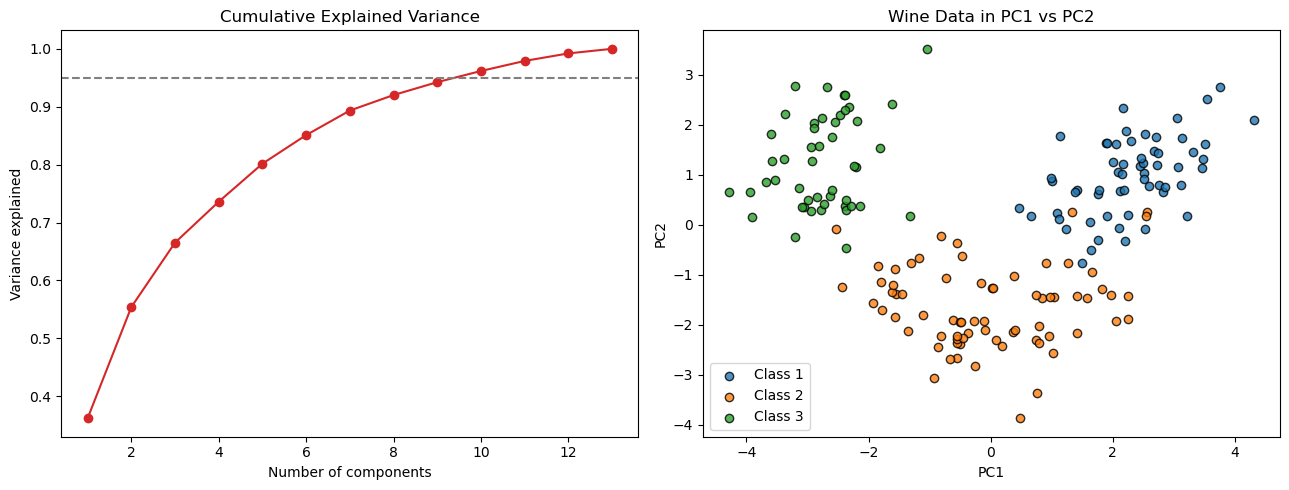

In [3]:
X_scaled = StandardScaler().fit_transform(X)

pca = PCA().fit(X_scaled)
cum_var = np.cumsum(pca.explained_variance_ratio_)
print(f"PC1 + PC2 explain {cum_var[1]:.1%} of the variance")
print(f"Components needed for 95% variance: {np.argmax(cum_var >= 0.95) + 1} of {X.shape[1]}")

X_pca = PCA(n_components=2).fit_transform(X_scaled)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].plot(range(1, len(cum_var) + 1), cum_var, marker="o", color="#d62728")
ax[0].axhline(0.95, ls="--", color="gray")
ax[0].set(title="Cumulative Explained Variance", xlabel="Number of components", ylabel="Variance explained")

for c in sorted(y.unique()):
    ax[1].scatter(*X_pca[(y == c).values].T, label=f"Class {c}", edgecolor="k", alpha=0.8)
ax[1].set(title="Wine Data in PC1 vs PC2", xlabel="PC1", ylabel="PC2")
ax[1].legend()
plt.tight_layout()
plt.show()

**Conclusion:** the first two principal components capture over half of the variance, and the three wine classes form largely separate clusters in the PC1–PC2 plot, so they can be told apart using just two components.

## Part B: LDA on Iris Dataset

Test accuracy: 100.00%

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



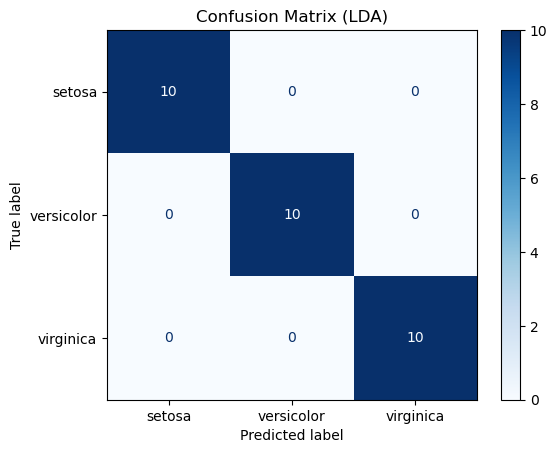

In [4]:
iris = load_iris(as_frame=True)
Xi = iris.data
yi = iris.target.map(dict(enumerate(iris.target_names)))

Xtr, Xte, ytr, yte = train_test_split(Xi, yi, test_size=0.2, random_state=42, stratify=yi)
lda = LinearDiscriminantAnalysis().fit(Xtr, ytr)
pred = lda.predict(Xte)

print(f"Test accuracy: {accuracy_score(yte, pred):.2%}\n")
print(classification_report(yte, pred))
ConfusionMatrixDisplay.from_predictions(yte, pred, cmap="Blues")
plt.title("Confusion Matrix (LDA)")
plt.show()

**Visualize the data in LDA space and classify a given flower.**

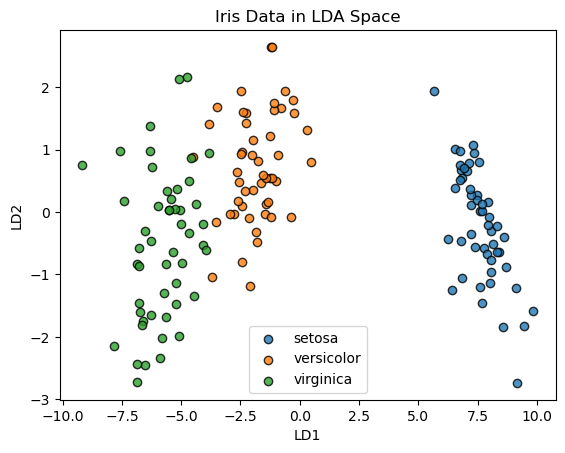

Predicted species: virginica


In [5]:
lda2 = LinearDiscriminantAnalysis(n_components=2).fit(Xi, yi)
X_ld = lda2.transform(Xi)

for sp in lda2.classes_:
    plt.scatter(*X_ld[(yi == sp).values].T, label=sp, edgecolor="k", alpha=0.8)
plt.title("Iris Data in LDA Space")
plt.xlabel("LD1"); plt.ylabel("LD2"); plt.legend()
plt.show()

# sepal length, sepal width, petal length, petal width (cm)
flower = pd.DataFrame([[5.9, 3.0, 5.1, 1.8]], columns=Xi.columns)
print("Predicted species:", lda2.predict(flower)[0])

**Conclusion:** LDA separates the three species well (setosa is fully separate; versicolor and virginica overlap slightly) and classifies unseen flowers accurately. PCA is unsupervised and keeps maximum variance, while LDA is supervised and keeps maximum class separation.